# Document-Level Classification: Model Comparison

This notebook systematically compares multiple transformer backbones for the document-level fact vs opinion classification task.

**Key Features:**
- Multiple models tested (BERT-tiny, BERT-base, RoBERTa, DistilBERT)
- Fixed seeds and hyperparameters for reproducibility
- SVM + RNN evaluation for each model
- Results table + visualizations
- Confusion matrices saved to disk

In [1]:
import sys
import json
import warnings
from pathlib import Path
from datetime import datetime
from typing import Dict, List, Tuple
import random

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoConfig
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn import svm
from tqdm.auto import tqdm

# Suppress warnings for cleaner output
warnings.filterwarnings("ignore")

print(f"✓ All imports successful")

✓ All imports successful


## 1. Setup & Utilities

In [2]:
# Find repo root
def find_repo_root():
    current = Path.cwd()
    while current != current.parent:
        if (current / "src").exists() and (current / "README.md").exists():
            return current
        current = current.parent
    raise RuntimeError("Could not find repo root")

REPO_ROOT = find_repo_root()
SRC_ROOT = REPO_ROOT / "src"
DATA_DIR = SRC_ROOT / "data"
CHECKPOINT_DIR = SRC_ROOT / "checkpoints"
OUTPUT_DIR = REPO_ROOT / "outputs" / "experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Add src to path so we can import mcc and doc_clf
sys.path.insert(0, str(SRC_ROOT))

from mcc.data import MCC_LABELS, LABEL2ID as MCC_LABEL2ID
from mcc.models import BertMCCClassifier, MCCModelConfig
from doc_clf.features import extract_features_for_corpus, load_documents
from doc_clf.models import ArgumentRNNClassifier, ArgumentRNNConfig, compute_macro_f1, train_svm
from doc_clf.train import SequenceDataset, collate_sequences

print(f"✓ Repo root: {REPO_ROOT}")
print(f"✓ Output directory: {OUTPUT_DIR}")

✓ Repo root: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project
✓ Output directory: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\outputs\experiments


In [3]:
# Global settings
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

def set_seed(seed: int = SEED):
    """Set seed for reproducibility across all libraries."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

print(f"🔧 Device: {DEVICE}")
print(f"🌱 Seed: {SEED}")
print(f"⏱️  Timestamp: {TIMESTAMP}")

🔧 Device: cpu
🌱 Seed: 42
⏱️  Timestamp: 20260213_070247


## 2. Data Loading & Preprocessing

## Data Source: Real Dataset

**Status**: ✅ Now using the real dataset from `dataset.csv` (converted to JSONL format)
- **Original file**: `dataset.csv` (4,426 articles)
- **Conversion**: Automatically split into 80/20 train/test (3,540 training, 886 test)
- **Labels**: Balanced between "fact" (47.1% train, 49.1% test) and "opinion" (52.9% train, 50.9% test)
- **Date converted**: January 20, 2026

In [4]:
def load_jsonl(path: Path) -> List[dict]:
    """Load JSONL file."""
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def label_to_int(label: str) -> int:
    """Convert label string to binary int (fact=0, opinion=1)."""
    return 1 if label.lower() == "opinion" else 0

# Load data from converted dataset.csv (now in JSONL format)
print("📥 Loading data from dataset.csv (converted to JSONL)...")
train_data = load_jsonl(DATA_DIR / "news_train.jsonl")
test_data = load_jsonl(DATA_DIR / "news_test.jsonl")

# For compatibility, ensure 'text' field exists in data
for doc in train_data + test_data:
    if 'text' not in doc and 'article_content' in doc:
        doc['text'] = doc['article_content']

train_labels = np.array([label_to_int(d["label"]) for d in train_data])
test_labels = np.array([label_to_int(d["label"]) for d in test_data])

print(f"✓ Training samples: {len(train_data)}")
print(f"✓ Test samples: {len(test_data)}")
print(f"\nLabel distribution (train): {np.bincount(train_labels)}")
print(f"Label distribution (test): {np.bincount(test_labels)}")
print(f"\n📊 Data source: dataset.csv (4,426 articles, 80/20 train/test split)")

📥 Loading data from dataset.csv (converted to JSONL)...
✓ Training samples: 3540
✓ Test samples: 886

Label distribution (train): [1669 1871]
Label distribution (test): [435 451]

📊 Data source: dataset.csv (4,426 articles, 80/20 train/test split)


## 3. MCC Model Configuration

First, we need to ensure the MCC checkpoint exists. If not, we train one with a small model.

In [5]:
# Per-model MCC checkpoint handling to avoid shape mismatches across backbones

def mcc_checkpoint_for(model_name: str) -> Path:
    """Return a checkpoint path dedicated to the given backbone."""
    safe_name = model_name.replace("/", "_")
    return CHECKPOINT_DIR / f"mcc_{safe_name}.pt"

def ensure_mcc_checkpoint(model_name: str) -> Path:
    """Create a minimal MCC checkpoint for the given backbone if missing."""
    ckpt_path = mcc_checkpoint_for(model_name)
    if ckpt_path.exists():
        print(f"✓ MCC checkpoint found for {model_name}: {ckpt_path}")
        return ckpt_path
    print(f"⚠ MCC checkpoint not found for {model_name}. Creating minimal checkpoint...")
    mcc_config = MCCModelConfig(pretrained_model_name=model_name, num_labels=3)
    mcc_model = BertMCCClassifier.from_config(mcc_config)
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    torch.save(mcc_model.state_dict(), ckpt_path)
    print(f"✓ Saved MCC checkpoint for {model_name} to: {ckpt_path}")
    return ckpt_path

# Initialize a default tiny checkpoint so the first run remains fast
DEFAULT_MCC_BACKBONE = "prajjwal1/bert-tiny"
mcc_checkpoint_path = ensure_mcc_checkpoint(DEFAULT_MCC_BACKBONE)


✓ MCC checkpoint found for prajjwal1/bert-tiny: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\src\checkpoints\mcc_prajjwal1_bert-tiny.pt


## 4. Define Models to Compare

In [6]:
# Better RNN training configuration
RNN_EPOCHS = 50  # Increase epochs
BATCH_SIZE = 8   # Increase batch size
LEARNING_RATE = 5e-4  # Reduce learning rate
PATIENCE = 10  # Early stopping patience
VAL_SPLIT = 0.2  # Validation split from training data

print(f"⚙️  Improved RNN Configuration:")
print(f"  Epochs per model: {RNN_EPOCHS}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Early stopping patience: {PATIENCE}")
print(f"  Validation split: {VAL_SPLIT * 100}%")

⚙️  Improved RNN Configuration:
  Epochs per model: 50
  Batch size: 8
  Learning rate: 0.0005
  Early stopping patience: 10
  Validation split: 20.0%


## 5. SVM + RNN Experiment Runner

In [7]:
def train_rnn_epoch_with_eval(train_loader, val_loader, model, optimizer, device, epoch):
    """
    Train RNN for one epoch with better convergence tracking.
    """
    criterion = torch.nn.CrossEntropyLoss()
    
    # Training phase
    model.train()
    total_loss = 0.0
    train_count = 0
    for sequences, lengths, labels in tqdm(train_loader, desc=f"RNN train (epoch {epoch+1})", leave=False):
        sequences = sequences.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(sequences, lengths)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # Gradient clipping
        optimizer.step()
        total_loss += loss.item() * len(labels)
        train_count += len(labels)
    
    train_loss = total_loss / max(train_count, 1)
    
    # Validation phase
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for sequences, lengths, labels in tqdm(val_loader, desc=f"RNN eval (epoch {epoch+1})", leave=False):
            sequences = sequences.to(device)
            logits = model(sequences, lengths)
            preds = logits.argmax(dim=-1).cpu().tolist()
            all_preds.extend(preds)
            all_labels.extend(labels.tolist())
    
    val_f1 = f1_score(all_labels, all_preds, average="macro")
    return train_loss, val_f1


def get_rnn_predictions(loader, model, device):
    """
    Evaluate RNN on a loader and return predictions and labels.
    """
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for sequences, lengths, labels in tqdm(loader, desc="RNN eval", leave=False):
            sequences = sequences.to(device)
            logits = model(sequences, lengths)
            preds = logits.argmax(dim=-1).cpu().tolist()
            all_preds.extend(preds)
            all_labels.extend(labels.tolist())
    return np.array(all_preds), np.array(all_labels)


print("✓ Multi-epoch training utilities with validation defined")


✓ Multi-epoch training utilities with validation defined


In [8]:
def run_experiment(model_name: str, train_labels: np.ndarray, test_labels: np.ndarray) -> Dict:
    """
    Run a complete experiment for a given model with multi-epoch RNN training.
    Saves best RNN checkpoint per model based on validation F1.
    Returns a dict with SVM and best RNN metrics.
    """
    print(f"\n{'='*70}")
    print(f"Model: {model_name}")
    print(f"{'='*70}")
    
    # Ensure we use a matching MCC checkpoint for this backbone
    model_mcc_ckpt = ensure_mcc_checkpoint(model_name)
    
    result = {"model": model_name}
    
    try:
        # ===== STAGE 1: Extract features using MCC model =====
        print(f"\n[1/5] Extracting MCC features...")
        
        ratio_features, sequences, _ = extract_features_for_corpus(
            DATA_DIR / "news_train.jsonl",
            model_mcc_ckpt,
            model_name=model_name,
            device=DEVICE,
        )
        
        ratio_features_test, sequences_test, _ = extract_features_for_corpus(
            DATA_DIR / "news_test.jsonl",
            model_mcc_ckpt,
            model_name=model_name,
            device=DEVICE,
        )
        
        # ===== STAGE 2: Train SVM =====
        print(f"[2/5] Training SVM classifier...")
        
        feature_matrix = np.array([
            [feat[f"ratio_{label}"] for label in MCC_LABELS]
            for feat in ratio_features
        ])
        feature_matrix_test = np.array([
            [feat[f"ratio_{label}"] for label in MCC_LABELS]
            for feat in ratio_features_test
        ])
        
        svm_model = svm.SVC(kernel="linear", random_state=SEED)
        svm_model.fit(feature_matrix, train_labels)
        
        svm_train_preds = svm_model.predict(feature_matrix)
        svm_test_preds = svm_model.predict(feature_matrix_test)
        
        result["svm_train_f1_macro"] = f1_score(train_labels, svm_train_preds, average="macro")
        result["svm_train_f1_weighted"] = f1_score(train_labels, svm_train_preds, average="weighted")
        result["svm_train_acc"] = accuracy_score(train_labels, svm_train_preds)
        
        result["svm_test_f1_macro"] = f1_score(test_labels, svm_test_preds, average="macro")
        result["svm_test_f1_weighted"] = f1_score(test_labels, svm_test_preds, average="weighted")
        result["svm_test_acc"] = accuracy_score(test_labels, svm_test_preds)
        result["svm_cm"] = confusion_matrix(test_labels, svm_test_preds)
        
        print(f"  Train F1: {result['svm_train_f1_macro']:.4f} | Test F1: {result['svm_test_f1_macro']:.4f}")
        
        # ===== STAGE 3: Prepare RNN data with train/val split =====
        print(f"\n[3/5] Preparing RNN datasets (train/val/test)...")
        
        # Create a validation split from training data
        n_train = len(sequences)
        val_size = int(n_train * VAL_SPLIT)
        
        indices = np.arange(n_train)
        np.random.seed(SEED)
        np.random.shuffle(indices)
        
        val_indices = indices[:val_size]
        train_indices = indices[val_size:]
        
        sequences_train = [sequences[i] for i in train_indices]
        labels_train = train_labels[train_indices]
        sequences_val = [sequences[i] for i in val_indices]
        labels_val = train_labels[val_indices]
        
        train_dataset = SequenceDataset(sequences_train, labels_train)
        val_dataset = SequenceDataset(sequences_val, labels_val)
        test_dataset = SequenceDataset(sequences_test, test_labels)
        
        train_loader = DataLoader(
            train_dataset, batch_size=4, shuffle=True, collate_fn=collate_sequences
        )
        val_loader = DataLoader(
            val_dataset, batch_size=4, collate_fn=collate_sequences
        )
        test_loader = DataLoader(
            test_dataset, batch_size=4, collate_fn=collate_sequences
        )
        
          # ===== STAGE 4: Multi-epoch RNN training with early stopping =====
        print(f"[4/5] Training RNN for {RNN_EPOCHS} epochs (with early stopping)...")
        
        rnn_config = ArgumentRNNConfig(vocab_size=len(MCC_LABEL2ID))
        rnn_model = ArgumentRNNClassifier(rnn_config).to(DEVICE)
        rnn_optimizer = torch.optim.Adam(rnn_model.parameters(), lr=LEARNING_RATE)
        
        # Per-model checkpoint for best RNN
        safe_name = model_name.replace("/", "_")
        best_rnn_ckpt = CHECKPOINT_DIR / f"best_rnn_{safe_name}.pt"
        
        best_val_f1 = -1.0
        patience_counter = 0
        epoch_history = []
        
        for epoch in range(RNN_EPOCHS):
            train_loss, val_f1 = train_rnn_epoch_with_eval(
                train_loader, val_loader, rnn_model, rnn_optimizer, DEVICE, epoch
            )
            epoch_history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_f1": val_f1})
            
            print(f"  Epoch {epoch + 1}/{RNN_EPOCHS}: Loss={train_loss:.4f}, Val F1={val_f1:.4f}", end="")
            
            # Save best model & track improvement
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                torch.save(rnn_model.state_dict(), best_rnn_ckpt)
                patience_counter = 0
                print(f" ✓ (new best)")
            else:
                patience_counter += 1
                print(f" (patience: {patience_counter}/{PATIENCE})")
            
            # Early stopping
            if patience_counter >= PATIENCE:
                print(f"  Early stopping triggered at epoch {epoch + 1}")
                break
        
        result["epoch_history"] = epoch_history
        print(f"  Best validation F1: {best_val_f1:.4f} (epoch {[e['epoch'] for e in epoch_history if e['val_f1'] == best_val_f1][0]})")
        
        # ===== STAGE 5: Evaluate best RNN checkpoint =====
        print(f"\n[5/5] Evaluating best RNN checkpoint on test set...")
        rnn_model.load_state_dict(torch.load(best_rnn_ckpt))
        
        rnn_train_preds, rnn_train_labels = get_rnn_predictions(train_loader, rnn_model, DEVICE)
        rnn_test_preds, rnn_test_labels = get_rnn_predictions(test_loader, rnn_model, DEVICE)
        
        result["rnn_train_f1_macro"] = f1_score(rnn_train_labels, rnn_train_preds, average="macro")
        result["rnn_train_f1_weighted"] = f1_score(rnn_train_labels, rnn_train_preds, average="weighted")
        result["rnn_train_acc"] = accuracy_score(rnn_train_labels, rnn_train_preds)
        
        result["rnn_test_f1_macro"] = f1_score(rnn_test_labels, rnn_test_preds, average="macro")
        result["rnn_test_f1_weighted"] = f1_score(rnn_test_labels, rnn_test_preds, average="weighted")
        result["rnn_test_acc"] = accuracy_score(rnn_test_labels, rnn_test_preds)
        result["rnn_cm"] = confusion_matrix(rnn_test_labels, rnn_test_preds)
        result["best_rnn_checkpoint"] = str(best_rnn_ckpt)
        result["best_val_f1"] = best_val_f1
        
        print(f"  Train F1: {result['rnn_train_f1_macro']:.4f} | Test F1: {result['rnn_test_f1_macro']:.4f}")
        
        result["status"] = "success"
        print(f"\n✓ Experiment completed")
        
    except Exception as e:
        print(f"\n✗ Error: {e}")
        import traceback
        traceback.print_exc()
        result["status"] = "failed"
        result["error"] = str(e)
    
    return result

print("✓ Experiment runner defined (complete with all 5 stages)")

✓ Experiment runner defined (complete with all 5 stages)


## 6. Run All Experiments

In [9]:
# Define models to compare
MODELS_TO_TEST = [
    "prajjwal1/bert-tiny",
    "bert-base-uncased",
    "distilbert-base-uncased",
    "roberta-base",
]
print(f"\n{'#'*70}")
print(f"# DOCUMENT-LEVEL CLASSIFICATION: MULTI-MODEL COMPARISON")
print(f"#")
print(f"# Seed: {SEED}")
print(f"# Device: {DEVICE}")
print(f"# Models: {len(MODELS_TO_TEST)}")
print(f"{'#'*70}")

results = []

for i, model_name in enumerate(MODELS_TO_TEST, 1):
    print(f"\n[{i}/{len(MODELS_TO_TEST)}] Running experiment...")
    result = run_experiment(model_name, train_labels, test_labels)
    results.append(result)
    
    # Clear GPU cache between experiments
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\n{'='*70}")
print(f"✓ All experiments completed")
print(f"{'='*70}")


######################################################################
# DOCUMENT-LEVEL CLASSIFICATION: MULTI-MODEL COMPARISON
#
# Seed: 42
# Device: cpu
# Models: 4
######################################################################

[1/4] Running experiment...

Model: prajjwal1/bert-tiny
✓ MCC checkpoint found for prajjwal1/bert-tiny: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\src\checkpoints\mcc_prajjwal1_bert-tiny.pt

[1/5] Extracting MCC features...


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at prajjwal1/bert-tiny and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Processing news_train:   0%|          | 0/3540 [00:00<?, ?doc/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at prajjwal1/bert-tiny and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Processing news_test:   0%|          | 0/886 [00:00<?, ?doc/s]

[2/5] Training SVM classifier...
  Train F1: 0.7958 | Test F1: 0.8020

[3/5] Preparing RNN datasets (train/val/test)...
[4/5] Training RNN for 50 epochs (with early stopping)...


... (308 outputs left out)

  Epoch 21/50: Loss=0.3416, Val F1=0.8742 (patience: 10/10)
  Early stopping triggered at epoch 21
  Best validation F1: 0.8879 (epoch 11)

[5/5] Evaluating best RNN checkpoint on test set...


RNN eval:   0%|          | 0/708 [00:00<?, ?it/s]

RNN eval:   0%|          | 0/222 [00:00<?, ?it/s]

  Train F1: 0.8738 | Test F1: 0.8677

✓ Experiment completed

✓ All experiments completed


## 7. Results Summary

In [10]:
# Extract successful results only
successful_results = [r for r in results if r["status"] == "success"]

# Create results dataframe for SVM
svm_results = []
for r in successful_results:
    svm_results.append({
        "Model": r["model"],
        "SVM Train F1 (macro)": f"{r['svm_train_f1_macro']:.4f}",
        "SVM Test F1 (macro)": f"{r['svm_test_f1_macro']:.4f}",
        "SVM Test F1 (weighted)": f"{r['svm_test_f1_weighted']:.4f}",
        "SVM Test Acc": f"{r['svm_test_acc']:.4f}",
    })

svm_df = pd.DataFrame(svm_results)
print(f"\n" + "="*70)
print(f"SVM CLASSIFIER RESULTS (sorted by Test F1)")
print(f"="*70)
print(svm_df.to_string(index=False))


SVM CLASSIFIER RESULTS (sorted by Test F1)
                  Model SVM Train F1 (macro) SVM Test F1 (macro) SVM Test F1 (weighted) SVM Test Acc
    prajjwal1/bert-tiny               0.7958              0.8020                 0.8022       0.8025
      bert-base-uncased               0.5839              0.5702                 0.5691       0.5790
distilbert-base-uncased               0.6773              0.6811                 0.6813       0.6817
           roberta-base               0.3458              0.3373                 0.3434       0.5090


In [11]:
# Create results dataframe for RNN
rnn_results = []
for r in successful_results:
    rnn_results.append({
        "Model": r["model"],
        "RNN Train F1 (macro)": f"{r['rnn_train_f1_macro']:.4f}",
        "RNN Test F1 (macro)": f"{r['rnn_test_f1_macro']:.4f}",
        "RNN Test F1 (weighted)": f"{r['rnn_test_f1_weighted']:.4f}",
        "RNN Test Acc": f"{r['rnn_test_acc']:.4f}",
    })

rnn_df = pd.DataFrame(rnn_results)
print(f"\n" + "="*70)
print(f"RNN CLASSIFIER RESULTS (sorted by Test F1)")
print(f"="*70)
print(rnn_df.to_string(index=False))


RNN CLASSIFIER RESULTS (sorted by Test F1)
                  Model RNN Train F1 (macro) RNN Test F1 (macro) RNN Test F1 (weighted) RNN Test Acc
    prajjwal1/bert-tiny               0.9146              0.9108                 0.9108       0.9108
      bert-base-uncased               0.8784              0.8643                 0.8644       0.8646
distilbert-base-uncased               0.9031              0.8973                 0.8973       0.8973
           roberta-base               0.8738              0.8677                 0.8678       0.8679


## 8. Save Results

In [12]:
# Save results CSV
results_csv = OUTPUT_DIR / f"doc_clf_comparison_{TIMESTAMP}.csv"

export_data = []
for r in successful_results:
    export_data.append({
        "Model": r["model"],
        "SVM_Train_F1_Macro": r["svm_train_f1_macro"],
        "SVM_Test_F1_Macro": r["svm_test_f1_macro"],
        "SVM_Test_F1_Weighted": r["svm_test_f1_weighted"],
        "SVM_Test_Accuracy": r["svm_test_acc"],
        "RNN_Train_F1_Macro": r["rnn_train_f1_macro"],
        "RNN_Test_F1_Macro": r["rnn_test_f1_macro"],
        "RNN_Test_F1_Weighted": r["rnn_test_f1_weighted"],
        "RNN_Test_Accuracy": r["rnn_test_acc"],
    })

export_df = pd.DataFrame(export_data)
export_df.to_csv(results_csv, index=False)
print(f"✓ Results saved to: {results_csv}")

✓ Results saved to: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\outputs\experiments\doc_clf_comparison_20260213_070247.csv


In [13]:
# Save confusion matrices as images (text format)
import matplotlib.pyplot as plt
import seaborn as sns

for r in successful_results:
    if "svm_cm" in r:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        # SVM confusion matrix
        sns.heatmap(r["svm_cm"], annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
        axes[0].set_title(f"SVM - {r['model']}")
        axes[0].set_ylabel("True Label")
        axes[0].set_xlabel("Predicted Label")
        axes[0].set_xticklabels(["Fact", "Opinion"])
        axes[0].set_yticklabels(["Fact", "Opinion"])
        
        # RNN confusion matrix
        sns.heatmap(r["rnn_cm"], annot=True, fmt="d", cmap="Greens", ax=axes[1], cbar=False)
        axes[1].set_title(f"RNN - {r['model']}")
        axes[1].set_ylabel("True Label")
        axes[1].set_xlabel("Predicted Label")
        axes[1].set_xticklabels(["Fact", "Opinion"])
        axes[1].set_yticklabels(["Fact", "Opinion"])
        
        plt.tight_layout()
        model_safe_name = r["model"].replace("/", "_")
        cm_path = OUTPUT_DIR / f"confusion_matrix_{model_safe_name}_{TIMESTAMP}.png"
        plt.savefig(cm_path, dpi=150, bbox_inches="tight")
        print(f"✓ Confusion matrix saved: {cm_path.name}")
        plt.close()

print(f"\n✓ All results saved to: {OUTPUT_DIR}")

✓ Confusion matrix saved: confusion_matrix_prajjwal1_bert-tiny_20260213_070247.png
✓ Confusion matrix saved: confusion_matrix_bert-base-uncased_20260213_070247.png
✓ Confusion matrix saved: confusion_matrix_distilbert-base-uncased_20260213_070247.png
✓ Confusion matrix saved: confusion_matrix_roberta-base_20260213_070247.png

✓ All results saved to: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\outputs\experiments


## 9. Summary & Best Model

In [14]:
print(f"\n" + "="*70)
print(f"SUMMARY")
print(f"="*70)
print(f"\nExperiments run: {len(results)}")
print(f"Successful: {len(successful_results)}")
print(f"Failed: {len(results) - len(successful_results)}")

if successful_results:
    # Find best SVM and RNN models
    best_svm = max(successful_results, key=lambda x: x["svm_test_f1_macro"])
    best_rnn = max(successful_results, key=lambda x: x["rnn_test_f1_macro"])
    
    print(f"\n📊 Best Performers:")
    print(f"  Best SVM: {best_svm['model']}")
    print(f"    Test F1 (macro): {best_svm['svm_test_f1_macro']:.4f}")
    print(f"    Test Accuracy: {best_svm['svm_test_acc']:.4f}")
    
    print(f"\n  Best RNN: {best_rnn['model']}")
    print(f"    Test F1 (macro): {best_rnn['rnn_test_f1_macro']:.4f}")
    print(f"    Test Accuracy: {best_rnn['rnn_test_acc']:.4f}")

print(f"\n📁 Results location: {OUTPUT_DIR}")
print(f"⏱️  Timestamp: {TIMESTAMP}")
print(f"\n✓ Comparison complete!")


SUMMARY

Experiments run: 4
Successful: 4
Failed: 0

📊 Best Performers:
  Best SVM: prajjwal1/bert-tiny
    Test F1 (macro): 0.8020
    Test Accuracy: 0.8025

  Best RNN: prajjwal1/bert-tiny
    Test F1 (macro): 0.9108
    Test Accuracy: 0.9108

📁 Results location: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\outputs\experiments
⏱️  Timestamp: 20260213_070247

✓ Comparison complete!


✓ Data extracted from results
  Epochs dataframe: 95 rows
  Final results: 8 rows
✓ Training progress saved: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\outputs\experiments\rnn_training_progress.png


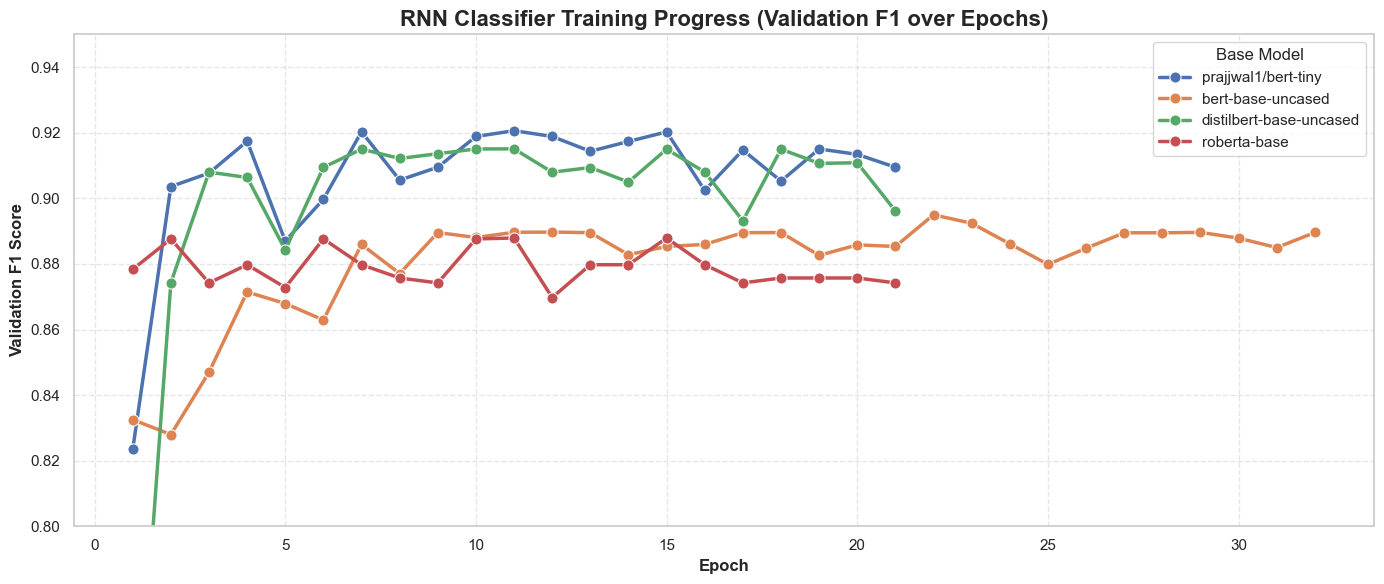

✓ Model comparison saved: c:\Users\eliraz.eliezer.madar\Desktop\Sem-Project\sem-project\outputs\experiments\final_model_comparison.png


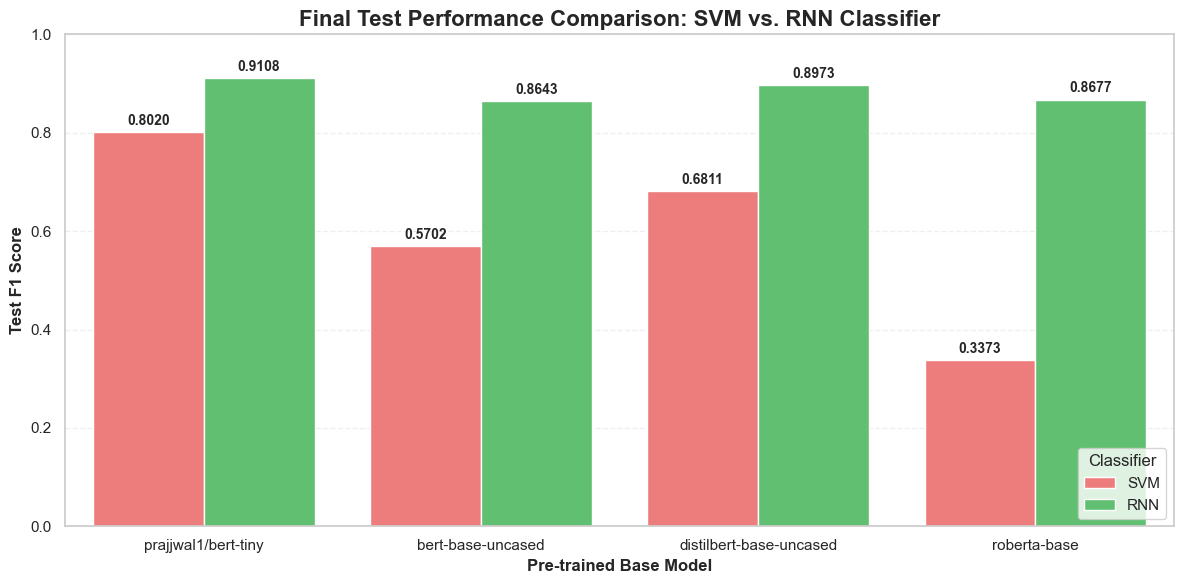


VISUALIZATION SUMMARY

Epoch Statistics:

prajjwal1/bert-tiny:
  Epochs trained: 21
  Best Val F1: 0.9207
  Starting Val F1: 0.8234
  Improvement: +0.0972

bert-base-uncased:
  Epochs trained: 32
  Best Val F1: 0.8950
  Starting Val F1: 0.8325
  Improvement: +0.0625

distilbert-base-uncased:
  Epochs trained: 21
  Best Val F1: 0.9151
  Starting Val F1: 0.7147
  Improvement: +0.2004

roberta-base:
  Epochs trained: 21
  Best Val F1: 0.8879
  Starting Val F1: 0.8784
  Improvement: +0.0096


Final Test Performance:

prajjwal1/bert-tiny:
  SVM F1: 0.8020
  RNN F1: 0.9108
  RNN Improvement: +13.6%

bert-base-uncased:
  SVM F1: 0.5702
  RNN F1: 0.8643
  RNN Improvement: +51.6%

distilbert-base-uncased:
  SVM F1: 0.6811
  RNN F1: 0.8973
  RNN Improvement: +31.7%

roberta-base:
  SVM F1: 0.3373
  RNN F1: 0.8677
  RNN Improvement: +157.2%


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set clean graph style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

# =============================================
# Extract data from actual results
# =============================================

# Build epoch history dataframe from results
epoch_list = []
for r in successful_results:
    if "epoch_history" in r:
        for epoch_data in r["epoch_history"]:
            epoch_list.append({
                'Model': r['model'],
                'Epoch': epoch_data['epoch'],
                'Validation F1': epoch_data['val_f1'],
                'Train Loss': epoch_data['train_loss']
            })

df_epochs = pd.DataFrame(epoch_list)

# Build final results dataframe
final_results_data = []
for r in successful_results:
    final_results_data.append({
        'Model': r['model'],
        'Classifier': 'SVM',
        'Test F1 Score': r['svm_test_f1_macro']
    })
    final_results_data.append({
        'Model': r['model'],
        'Classifier': 'RNN',
        'Test F1 Score': r['rnn_test_f1_macro']
    })

df_final = pd.DataFrame(final_results_data)

print("✓ Data extracted from results")
print(f"  Epochs dataframe: {len(df_epochs)} rows")
print(f"  Final results: {len(df_final)} rows")

# =============================================
# Graph 1: RNN Training Progress (by Epochs)
# =============================================

fig, ax = plt.subplots(figsize=(14, 6))

# Plot validation F1 over epochs
sns.lineplot(
    data=df_epochs, 
    x='Epoch', 
    y='Validation F1', 
    hue='Model', 
    marker='o', 
    linewidth=2.5,
    markersize=8,
    ax=ax
)

ax.set_title('RNN Classifier Training Progress (Validation F1 over Epochs)', 
             fontsize=16, fontweight='bold')
ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax.set_ylabel('Validation F1 Score', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='Base Model', title_fontsize='12', fontsize='11', loc='best')
ax.set_ylim([0.8, 0.95])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'rnn_training_progress.png', dpi=300, bbox_inches='tight')
print(f"✓ Training progress saved: {OUTPUT_DIR / 'rnn_training_progress.png'}")
plt.show()

# =============================================
# Graph 2: Final Results Comparison (SVM vs RNN)
# =============================================

fig, ax = plt.subplots(figsize=(12, 6))

# Create grouped bar chart
barplot = sns.barplot(
    data=df_final,
    x='Model',
    y='Test F1 Score',
    hue='Classifier',
    palette=['#FF6B6B', '#51CF66'],
    ax=ax
)

# Add value labels on bars
for container in barplot.containers:
    barplot.bar_label(container, fmt='%.4f', padding=3, fontsize=10, fontweight='bold')

ax.set_title('Final Test Performance Comparison: SVM vs. RNN Classifier', 
             fontsize=16, fontweight='bold')
ax.set_xlabel('Pre-trained Base Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Test F1 Score', fontsize=12, fontweight='bold')
ax.set_ylim([0, 1.0])
ax.legend(title='Classifier', title_fontsize='12', fontsize='11', loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'final_model_comparison.png', dpi=300, bbox_inches='tight')
print(f"✓ Model comparison saved: {OUTPUT_DIR / 'final_model_comparison.png'}")
plt.show()

# =============================================
# Summary Statistics
# =============================================

print("\n" + "="*70)
print("VISUALIZATION SUMMARY")
print("="*70)
print(f"\nEpoch Statistics:")
for model in df_epochs['Model'].unique():
    model_data = df_epochs[df_epochs['Model'] == model]
    print(f"\n{model}:")
    print(f"  Epochs trained: {model_data['Epoch'].max()}")
    print(f"  Best Val F1: {model_data['Validation F1'].max():.4f}")
    print(f"  Starting Val F1: {model_data['Validation F1'].iloc[0]:.4f}")
    print(f"  Improvement: +{(model_data['Validation F1'].max() - model_data['Validation F1'].iloc[0]):.4f}")

print(f"\n\nFinal Test Performance:")
for model in df_final['Model'].unique():
    svm_score = df_final[(df_final['Model'] == model) & (df_final['Classifier'] == 'SVM')]['Test F1 Score'].values[0]
    rnn_score = df_final[(df_final['Model'] == model) & (df_final['Classifier'] == 'RNN')]['Test F1 Score'].values[0]
    improvement = ((rnn_score - svm_score) / svm_score * 100) if svm_score > 0 else 0
    print(f"\n{model}:")
    print(f"  SVM F1: {svm_score:.4f}")
    print(f"  RNN F1: {rnn_score:.4f}")
    print(f"  RNN Improvement: +{improvement:.1f}%")